In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("All libraries imported successfully!")


All libraries imported successfully!


In [2]:

# Load Breast Cancer dataset
data = load_breast_cancer()

X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

print("Dataset loaded successfully!")
print("Number of rows and columns:", X.shape)

print("\nFirst five records:")
print(X.head())

print("\nTarget classes:", data.target_names)


Dataset loaded successfully!
Number of rows and columns: (569, 30)

First five records:
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   m

In [3]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))


Training records: 455
Testing records: 114


In [4]:

models = {
    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", SVC())
    ]),

    "Random Forest": RandomForestClassifier(
        random_state=42
    ),

    "AdaBoost": AdaBoostClassifier(
        random_state=42
    )
}

print("SVM, Random Forest and AdaBoost models created.")


SVM, Random Forest and AdaBoost models created.


In [5]:

results = []
best_models = {}

for name, model in models.items():

    print("\n------------------------------")
    print("Model:", name)
    print("------------------------------")

    # 5-fold cross-validation
    cv_scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=5,
        scoring="accuracy"
    )

    print("Cross-validation scores:", np.round(cv_scores, 4))
    print("Mean CV accuracy:", round(cv_scores.mean(), 4))

    # Train the default model
    model.fit(X_train, y_train)

    # Predict test data
    y_pred = model.predict(X_test)

    # Store evaluation results
    results.append({
        "Model": name,
        "Stage": "Before Optimization",
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-score": f1_score(y_test, y_pred),
        "CV Accuracy": cv_scores.mean()
    })

    print("\nClassification Report:")
    print(classification_report(
        y_test,
        y_pred,
        target_names=data.target_names
    ))

print("All default models evaluated.")



------------------------------
Model: SVM
------------------------------
Cross-validation scores: [0.956  0.989  0.9451 0.978  0.989 ]
Mean CV accuracy: 0.9714

Classification Report:
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114


------------------------------
Model: Random Forest
------------------------------
Cross-validation scores: [0.967  0.989  0.9231 0.9341 0.956 ]
Mean CV accuracy: 0.9538

Classification Report:
              precision    recall  f1-score   support

   malignant       0.95      0.93      0.94        42
      benign       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.

In [6]:

param_grids = {
    "SVM": {
        "classifier__C": [0.1, 1, 10],
        "classifier__kernel": ["linear", "rbf"],
        "classifier__gamma": ["scale", "auto"]
    },

    "Random Forest": {
        "n_estimators": [50, 100],
        "max_depth": [None, 5, 10],
        "min_samples_split": [2, 5]
    },

    "AdaBoost": {
        "n_estimators": [50, 100],
        "learning_rate": [0.1, 1.0]
    }
}

for name, model in models.items():

    print("\n------------------------------")
    print("Optimizing:", name)
    print("------------------------------")

    grid = GridSearchCV(
        estimator=model,
        param_grid=param_grids[name],
        cv=5,
        scoring="accuracy",
        n_jobs=-1
    )

    grid.fit(X_train, y_train)

    best_model = grid.best_estimator_
    best_models[name] = best_model

    print("Best parameters:", grid.best_params_)
    print("Best CV accuracy:", round(grid.best_score_, 4))

    # Prediction after optimization
    y_pred = best_model.predict(X_test)

    # Store optimized results
    results.append({
        "Model": name,
        "Stage": "After Optimization",
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-score": f1_score(y_test, y_pred),
        "CV Accuracy": grid.best_score_
    })

    print("\nOptimized Classification Report:")
    print(classification_report(
        y_test,
        y_pred,
        target_names=data.target_names
    ))

print("Hyperparameter tuning completed.")



------------------------------
Optimizing: SVM
------------------------------
Best parameters: {'classifier__C': 0.1, 'classifier__gamma': 'scale', 'classifier__kernel': 'linear'}
Best CV accuracy: 0.978

Optimized Classification Report:
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114


------------------------------
Optimizing: Random Forest
------------------------------
Best parameters: {'max_depth': None, 'min_samples_split': 5, 'n_estimators': 50}
Best CV accuracy: 0.9582

Optimized Classification Report:
              precision    recall  f1-score   support

   malignant       0.93      0.93      0.93        42
      benign       0.96      0.96      0.96        72

    accuracy                           0.

In [7]:

results_df = pd.DataFrame(results)

print("FINAL MODEL COMPARISON")
display(results_df.round(4))


FINAL MODEL COMPARISON


,Model,Stage,Accuracy,Precision,Recall,F1-score,CV Accuracy
0,SVM,Before Optimization,0.9825,0.9861,0.9861,0.9861,0.9714
1,Random Forest,Before Optimization,0.9561,0.9589,0.9722,0.9655,0.9538
2,AdaBoost,Before Optimization,0.9561,0.9467,0.9861,0.9660,0.9692
3,SVM,After Optimization,0.9825,0.9861,0.9861,0.9861,0.9780
4,Random Forest,After Optimization,0.9474,0.9583,0.9583,0.9583,0.9582
5,AdaBoost,After Optimization,0.9561,0.9467,0.9861,0.9660,0.9736


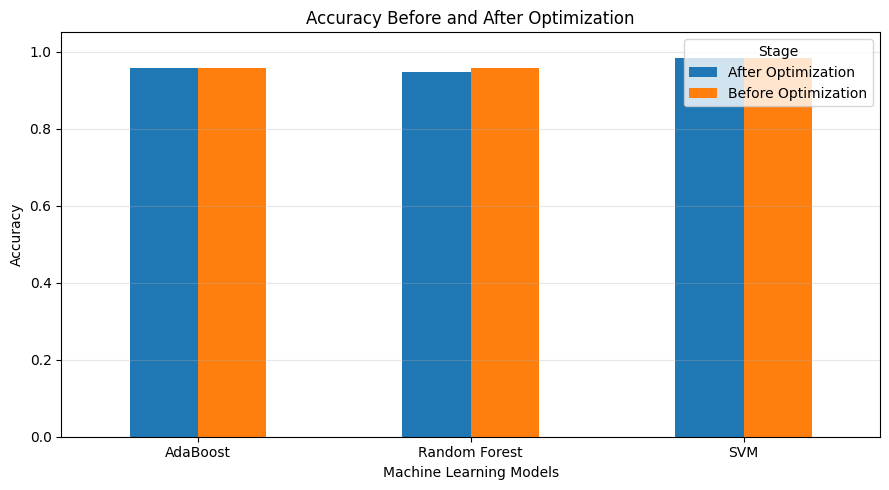

In [8]:

accuracy_table = results_df.pivot(
    index="Model",
    columns="Stage",
    values="Accuracy"
)

accuracy_table.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Accuracy Before and After Optimization")
plt.xlabel("Machine Learning Models")
plt.ylabel("Accuracy")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


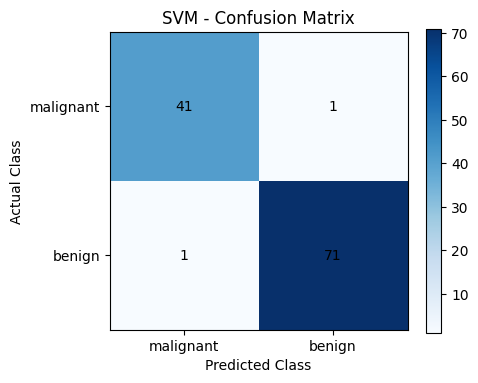

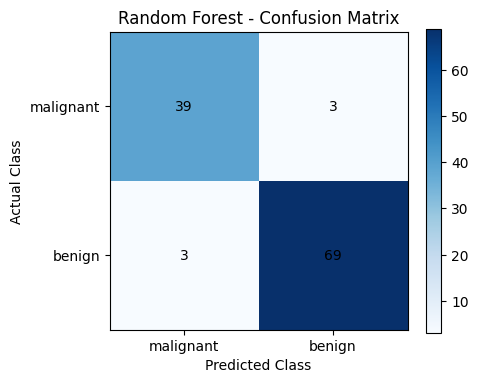

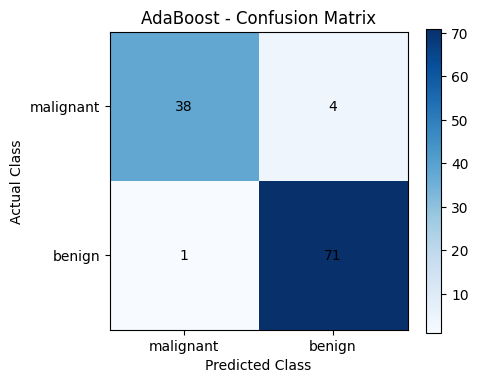

In [9]:

for name, model in best_models.items():

    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(5, 4))
    plt.imshow(cm, interpolation="nearest", cmap="Blues")
    plt.title(name + " - Confusion Matrix")
    plt.colorbar()

    plt.xticks([0, 1], data.target_names, rotation=0)
    plt.yticks([0, 1], data.target_names)

    for i in range(2):
        for j in range(2):
            plt.text(
                j, i, cm[i, j],
                ha="center", va="center",
                color="black"
            )

    plt.xlabel("Predicted Class")
    plt.ylabel("Actual Class")
    plt.tight_layout()
    plt.show()


In [10]:

optimized_results = results_df[
    results_df["Stage"] == "After Optimization"
]

best_row = optimized_results.sort_values(
    by="F1-score",
    ascending=False
).iloc[0]

print("Best Model:", best_row["Model"])
print("Accuracy:", round(best_row["Accuracy"], 4))
print("Precision:", round(best_row["Precision"], 4))
print("Recall:", round(best_row["Recall"], 4))
print("F1-score:", round(best_row["F1-score"], 4))


Best Model: SVM
Accuracy: 0.9825
Precision: 0.9861
Recall: 0.9861
F1-score: 0.9861
